# Model 1: Basic CNN: CNN denoiser (step 1 of 2)

Trains the CNN and saves the best version to `SAVE_DIR`. Run the matching **GAN notebook** afterwards.

Cells from the top down to *Load data* and the helper cell are identical in every notebook. Only the model cell and the hyperparameter grid differ per model.

**Changes from the original:** one checkpoint per hyperparameter setting (the old code overwrote one file, so the GAN loaded the last setting, not the best); metrics compare against the normal-light target and average over all images; no meaningless `accuracy` metric; optional early stopping; `.keras` format.

In [ ]:
# Mount Google Drive when running in Colab (skipped automatically anywhere else)
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab - using the paths from the CONFIG cell')

Mounted at /content/drive


In [ ]:
import os, gc, json, shutil
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import backend as K
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.layers import (Input, Conv2D, Conv2DTranspose, UpSampling2D, MaxPooling2D,
                                     BatchNormalization, Activation, ReLU, LeakyReLU, Concatenate,
                                     Flatten, Dense, Reshape, GlobalAveragePooling2D)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from tensorflow.keras.utils import load_img, img_to_array
from sklearn.model_selection import train_test_split, ParameterGrid

In [ ]:
# ============================== CONFIG (edit paths here only) ==============================
MODEL_NAME = 'model1_basic_cnn'
DATA_PATH  = '/content/drive/MyDrive/LOL_dataset/lol_dataset/'   # folder containing our485/ and eval15/
SAVE_DIR   = '/content/drive/MyDrive/lowlight_models/'           # where trained models are saved
IMG_SIZE   = (200, 300)    # (height, width). Try (200, 300) for a roughly 4x faster run on CPU
SEED       = 42
PATIENCE   = 10      # early stopping patience in epochs (None = always train all epochs)
CNN_BEST_PATH = os.path.join(SAVE_DIR, MODEL_NAME + '_cnn_best.keras')   # read by the GAN notebook
# ===========================================================================================

os.makedirs(SAVE_DIR, exist_ok=True)
input_shape = (*IMG_SIZE, 3)
tf.keras.utils.set_random_seed(SEED)

# Let TensorFlow grow GPU memory as needed (the old fixed 39 GB limit only fits an A100)
for gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)
print('GPUs available:', len(tf.config.list_physical_devices('GPU')))

GPUs available: 1


## Load data

In [ ]:
def load_images(folder):
    folder_path = os.path.join(DATA_PATH, folder)
    images = []
    for filename in sorted(os.listdir(folder_path)):      # sorted, so low/high images stay paired
        img = load_img(os.path.join(folder_path, filename), target_size=IMG_SIZE)
        images.append(img_to_array(img) / 255.0)          # scale pixels to [0, 1]
    return np.array(images, dtype='float32')

low_all  = load_images('our485/low')
high_all = load_images('our485/high')

# One call splits both arrays with the same shuffle (same 80/20 split as the original notebook)
(train_low_light_images, val_low_light_images,
 train_normal_light_images, val_normal_light_images) = train_test_split(
    low_all, high_all, test_size=0.2, random_state=SEED)
del low_all, high_all

test_low_light_images    = load_images('eval15/low')
test_normal_light_images = load_images('eval15/high')

print('train:', train_low_light_images.shape, '| val:', val_low_light_images.shape,
      '| test:', test_low_light_images.shape)

train: (388, 200, 300, 3) | val: (97, 200, 300, 3) | test: (15, 200, 300, 3)


In [ ]:
def score(reference, prediction, batch=8):
    """MSE / PSNR / SSIM averaged over ALL images (pixel range 0-1), compared with the normal-light target."""
    mses, psnrs, ssims = [], [], []
    for i in range(0, len(reference), batch):
        ref = reference[i:i + batch]
        pred = np.clip(prediction[i:i + batch], 0.0, 1.0)
        mses.append(np.mean((ref - pred) ** 2, axis=(1, 2, 3)))
        psnrs.append(tf.image.psnr(ref, pred, max_val=1.0).numpy())
        ssims.append(tf.image.ssim(ref, pred, max_val=1.0).numpy())
    return {'mse':  float(np.concatenate(mses).mean()),
            'psnr': float(np.concatenate(psnrs).mean()),
            'ssim': float(np.concatenate(ssims).mean())}

def show_results(columns, titles, n=3):
    """Plot n rows of images; each entry of `columns` is an array of images, one column per entry."""
    fig, axes = plt.subplots(n, len(columns), figsize=(4 * len(columns), 2.8 * n), squeeze=False)
    for i in range(n):
        for j, (imgs, title) in enumerate(zip(columns, titles)):
            axes[i, j].imshow(np.clip(imgs[i], 0, 1))
            axes[i, j].axis('off')
            if i == 0:
                axes[i, j].set_title(title)
    plt.tight_layout()
    plt.show()

## Model

In [ ]:
# Model 1: Basic CNN (encoder-decoder). Fully convolutional, so image height/width must be even.
def build_model():
    model = Sequential(name=MODEL_NAME)
    model.add(Input(shape=(None, None, 3)))

    # Encoder
    model.add(Conv2D(64, (3, 3), activation='relu', padding='same'))
    model.add(BatchNormalization())
    model.add(Conv2D(128, (3, 3), activation='relu', padding='same'))
    model.add(BatchNormalization())
    model.add(MaxPooling2D((2, 2), padding='same'))

    # Decoder
    model.add(Conv2DTranspose(128, (3, 3), activation='relu', padding='same'))
    model.add(BatchNormalization())
    model.add(Conv2DTranspose(64, (3, 3), activation='relu', padding='same'))
    model.add(BatchNormalization())
    model.add(UpSampling2D((2, 2)))

    # Output layer
    model.add(Conv2D(3, (3, 3), activation='sigmoid', padding='same'))
    return model

build_model().summary()

Model: "model1_basic_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, None, None, 64) │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, None, None, 64) │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, None, None,     │        73,856 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, None, None,     │           512 │
│ (BatchNormalization)            │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, None, None,     │             0 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, None, None,     │       147,584 │
│ (Conv2DTranspose)               │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, None, None,     │           512 │
│ (BatchNormalization)            │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, None, None, 64) │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, None, None, 64) │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, None, None, 64) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, None, None, 3)  │         1,731 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 300,291 (1.15 MB)

 Trainable params: 299,523 (1.14 MB)

 Non-trainable params: 768 (3.00 KB)

## Train (hyperparameter sweep)

In [ ]:
def train_one(params):
    """Train one hyperparameter setting. Returns its validation scores and the checkpoint path."""
    K.clear_session()
    model = build_model()
    model.compile(optimizer=Adam(learning_rate=params['learning_rate']), loss='mse')

    tag = f"lr{params['learning_rate']}_bs{params['batch_size']}_ep{params['epochs']}"
    ckpt = os.path.join(SAVE_DIR, f'{MODEL_NAME}_cnn_{tag}.keras')     # one file per setting
    callbacks = [ModelCheckpoint(ckpt, monitor='val_loss', save_best_only=True)]
    if PATIENCE:
        callbacks.append(EarlyStopping(monitor='val_loss', patience=PATIENCE))

    model.fit(train_low_light_images, train_normal_light_images,
              epochs=params['epochs'], batch_size=params['batch_size'],
              validation_data=(val_low_light_images, val_normal_light_images),
              callbacks=callbacks)

    best_epoch_model = load_model(ckpt, compile=False)                  # best epoch, not the last one
    val_pred = best_epoch_model.predict(val_low_light_images, batch_size=8, verbose=0)
    return {'params': params, 'ckpt': ckpt, **score(val_normal_light_images, val_pred)}

In [ ]:
param_grid = {'learning_rate': [0.01, 0.001, 0.0001], 'epochs': [50], 'batch_size': [8]}

In [ ]:
results = []
for params in ParameterGrid(param_grid):
    r = train_one(params)
    results.append(r)
    print(f"{r['params']} -> val MSE {r['mse']:.5f} | PSNR {r['psnr']:.2f} dB | SSIM {r['ssim']:.4f}")
    gc.collect()

# Keep the best setting (highest validation PSNR) under one fixed name, for the GAN notebook
best_run = max(results, key=lambda r: r['psnr'])
shutil.copy(best_run['ckpt'], CNN_BEST_PATH)
with open(os.path.join(SAVE_DIR, f'{MODEL_NAME}_cnn_results.json'), 'w') as f:
    json.dump(results, f, indent=2)
print('\nBest setting:', best_run['params'], '\nSaved to:', CNN_BEST_PATH)

Epoch 1/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 53s 555ms/step - loss: 0.0643 - val_loss: 0.1478
Epoch 2/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 161ms/step - loss: 0.0366 - val_loss: 0.0591
Epoch 3/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 162ms/step - loss: 0.0314 - val_loss: 0.0475
Epoch 4/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 161ms/step - loss: 0.0286 - val_loss: 0.0405
Epoch 5/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 162ms/step - loss: 0.0272 - val_loss: 0.0358
Epoch 6/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 9s 173ms/step - loss: 0.0277 - val_loss: 0.0362
Epoch 7/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 161ms/step - loss: 0.0265 - val_loss: 0.0332
Epoch 8/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 163ms/step - loss: 0.0254 - val_loss: 0.0298
Epoch 9/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 162ms/step - loss: 0.0249 - val_loss: 0.0285
Epoch 10/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 163ms/step - loss: 0.0244 - val_loss: 0.0286
Epoch 11/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 163ms/step - loss: 0.0240 - val_loss: 0.0328
Epoch 12/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 162ms/ste

## Test

Input (no model): {'mse': 0.19401948153972626, 'psnr': 7.772937297821045, 'ssim': 0.1795925498008728}
CNN             : {'mse': 0.0224186722189188, 'psnr': 17.330949783325195, 'ssim': 0.6908124089241028}


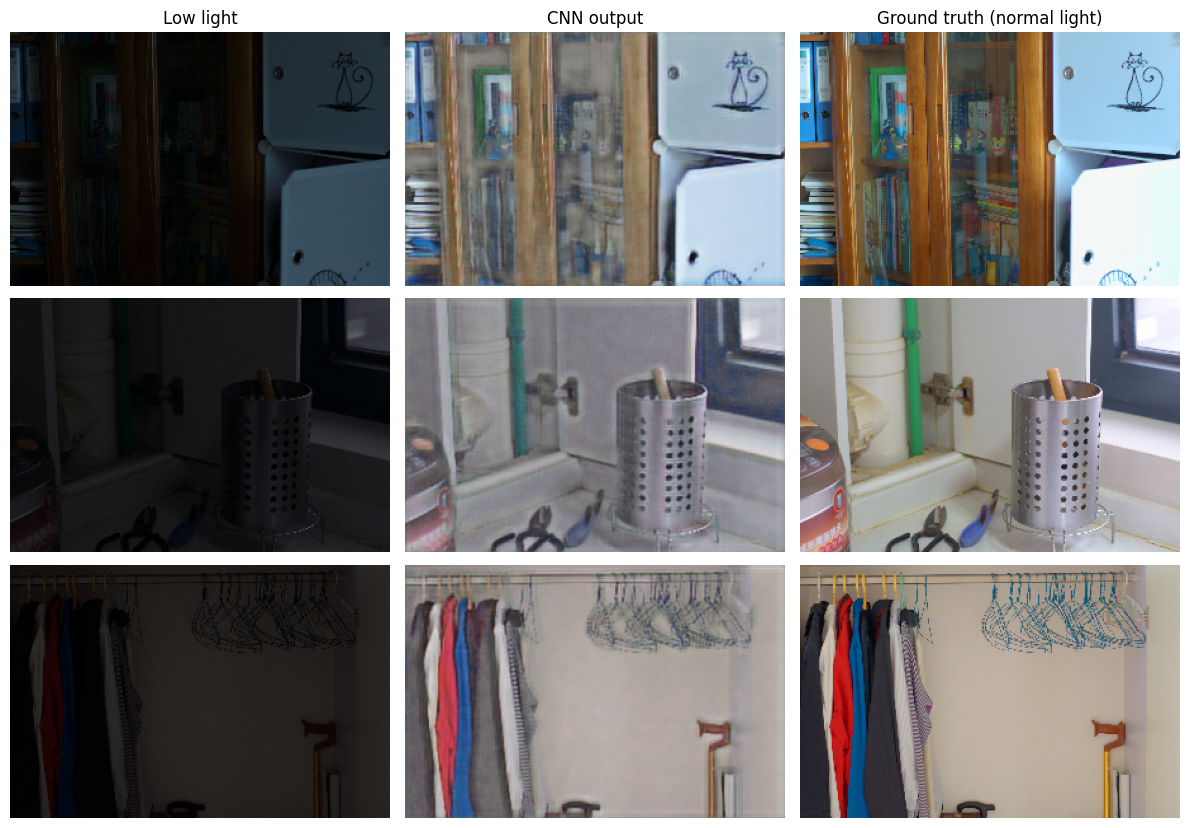

In [ ]:
# Final check on the 15 held-out test images
best_model = load_model(CNN_BEST_PATH, compile=False)
test_pred = best_model.predict(test_low_light_images, batch_size=8, verbose=0)

test_scores = {'input': score(test_normal_light_images, test_low_light_images),
               'cnn':   score(test_normal_light_images, test_pred)}
print('Input (no model):', test_scores['input'])
print('CNN             :', test_scores['cnn'])

# Saved so a final summary can compare all models side by side
with open(os.path.join(SAVE_DIR, f'{MODEL_NAME}_cnn_test.json'), 'w') as f:
    json.dump(test_scores, f, indent=2)

show_results([test_low_light_images, test_pred, test_normal_light_images],
             ['Low light', 'CNN output', 'Ground truth (normal light)'])